# 02 · Baseline prompt → image test runs
**Milestone 1 deliverable: 5 sample prompt→image runs**

Uses **Stable Diffusion 1.5** conditioned on the CLIP embeddings cached in notebook 01.
Every run uses a fixed seed and logs its settings so results are reproducible.

> Needs a GPU. On a Colab T4, each 512×512 image takes roughly 5–10 s at 30 steps.

In [1]:
# --- Setup: works in Google Colab and locally ---
import os, sys
from pathlib import Path

REPO_URL = "https://github.com/HiralR2931/Generative_Project_DeepLearning.git"
REPO_DIR = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")   # -> Generative_Project_DeepLearning
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    os.chdir("/content")
    if Path(REPO_DIR).exists() and not Path(REPO_DIR, "requirements.txt").exists():
        !rm -rf {REPO_DIR}          # remove an earlier empty clone
    if not Path(REPO_DIR).exists():
        !git clone -q {REPO_URL}
    os.chdir(REPO_DIR)
    !pip install -q -r requirements.txt
elif Path.cwd().name == "notebooks":
    os.chdir("..")              # run from repo root locally

sys.path.insert(0, os.getcwd())
print("Working dir:", os.getcwd())
assert Path("requirements.txt").exists(), "Repo looks empty: push the files to GitHub first."

Working dir: /Users/hiralr/Desktop/Generative_Project/Generative_Project_DeepLearning


In [2]:
import json, torch
import matplotlib.pyplot as plt
import pandas as pd
from src import config as C
from src.data import load_image
from src.generate import load_pipeline, generate, save_run

pipe = load_pipeline(C.SD_MODEL, scheduler=C.SCHEDULER)
print("Loaded on", pipe.device, "| scheduler:", type(pipe.scheduler).__name__)

/opt/miniconda3/envs/mlops_lab3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1106 18:21:57.649000 5132 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.
/opt/miniconda3/envs/mlops_lab3/lib/python3.10/site-packag

Loaded on cpu | scheduler: DPMSolverMultistepScheduler


## 1. Pick 5 COCO captions as prompts

In [3]:
emb = torch.load(C.PROC_DIR / "clip_text_1k.pt")
subset = pd.read_json(C.PROC_DIR / "pairs_1k.json")

idx = torch.Generator().manual_seed(C.SEED)
pick = torch.randperm(len(emb["captions"]), generator=idx)[:5].tolist()
prompts = [emb["captions"][i] for i in pick]
prompt_embeds = emb["hidden"][pick]           # (5, 77, 768) from our own pipeline
for i, p in enumerate(prompts): print(i, p)

0 Looks like the ingredients for a recipe including bananas
1 The man is holding an object in his hand
2 A glass vase with some flowers inside of it
3 Person on tennis court preparing to return a volley
4 A man standing next to a horse in the woods


## 2. Generate from our cached CLIP embeddings

In [4]:
settings = dict(model=C.SD_MODEL, scheduler=C.SCHEDULER, guidance_scale=C.GUIDANCE_SCALE,
                num_steps=C.NUM_STEPS, seed=C.SEED, size=C.IMAGE_SIZE, conditioning="cached CLIP ViT-L/14 hidden states")

images, secs = generate(pipe, prompt_embeds=prompt_embeds, guidance_scale=C.GUIDANCE_SCALE,
                        num_steps=C.NUM_STEPS, seed=C.SEED, size=C.IMAGE_SIZE)
print(f"Generated {len(images)} images in {secs:.1f}s ({secs/len(images):.1f}s each)")
save_run(images, prompts, C.SAMPLES_DIR, settings, prefix="baseline")

Generated 5 images in 711.5s (142.3s each)


[{'file': 'baseline_00.png',
  'prompt': 'Looks like the ingredients for a recipe including bananas',
  'model': 'stable-diffusion-v1-5/stable-diffusion-v1-5',
  'scheduler': 'dpm++',
  'guidance_scale': 7.5,
  'num_steps': 30,
  'seed': 42,
  'size': 512,
  'conditioning': 'cached CLIP ViT-L/14 hidden states'},
 {'file': 'baseline_01.png',
  'prompt': 'The man is holding an object in his hand',
  'model': 'stable-diffusion-v1-5/stable-diffusion-v1-5',
  'scheduler': 'dpm++',
  'guidance_scale': 7.5,
  'num_steps': 30,
  'seed': 42,
  'size': 512,
  'conditioning': 'cached CLIP ViT-L/14 hidden states'},
 {'file': 'baseline_02.png',
  'prompt': 'A glass vase with some flowers inside of it',
  'model': 'stable-diffusion-v1-5/stable-diffusion-v1-5',
  'scheduler': 'dpm++',
  'guidance_scale': 7.5,
  'num_steps': 30,
  'seed': 42,
  'size': 512,
  'conditioning': 'cached CLIP ViT-L/14 hidden states'},
 {'file': 'baseline_03.png',
  'prompt': 'Person on tennis court preparing to return a vo

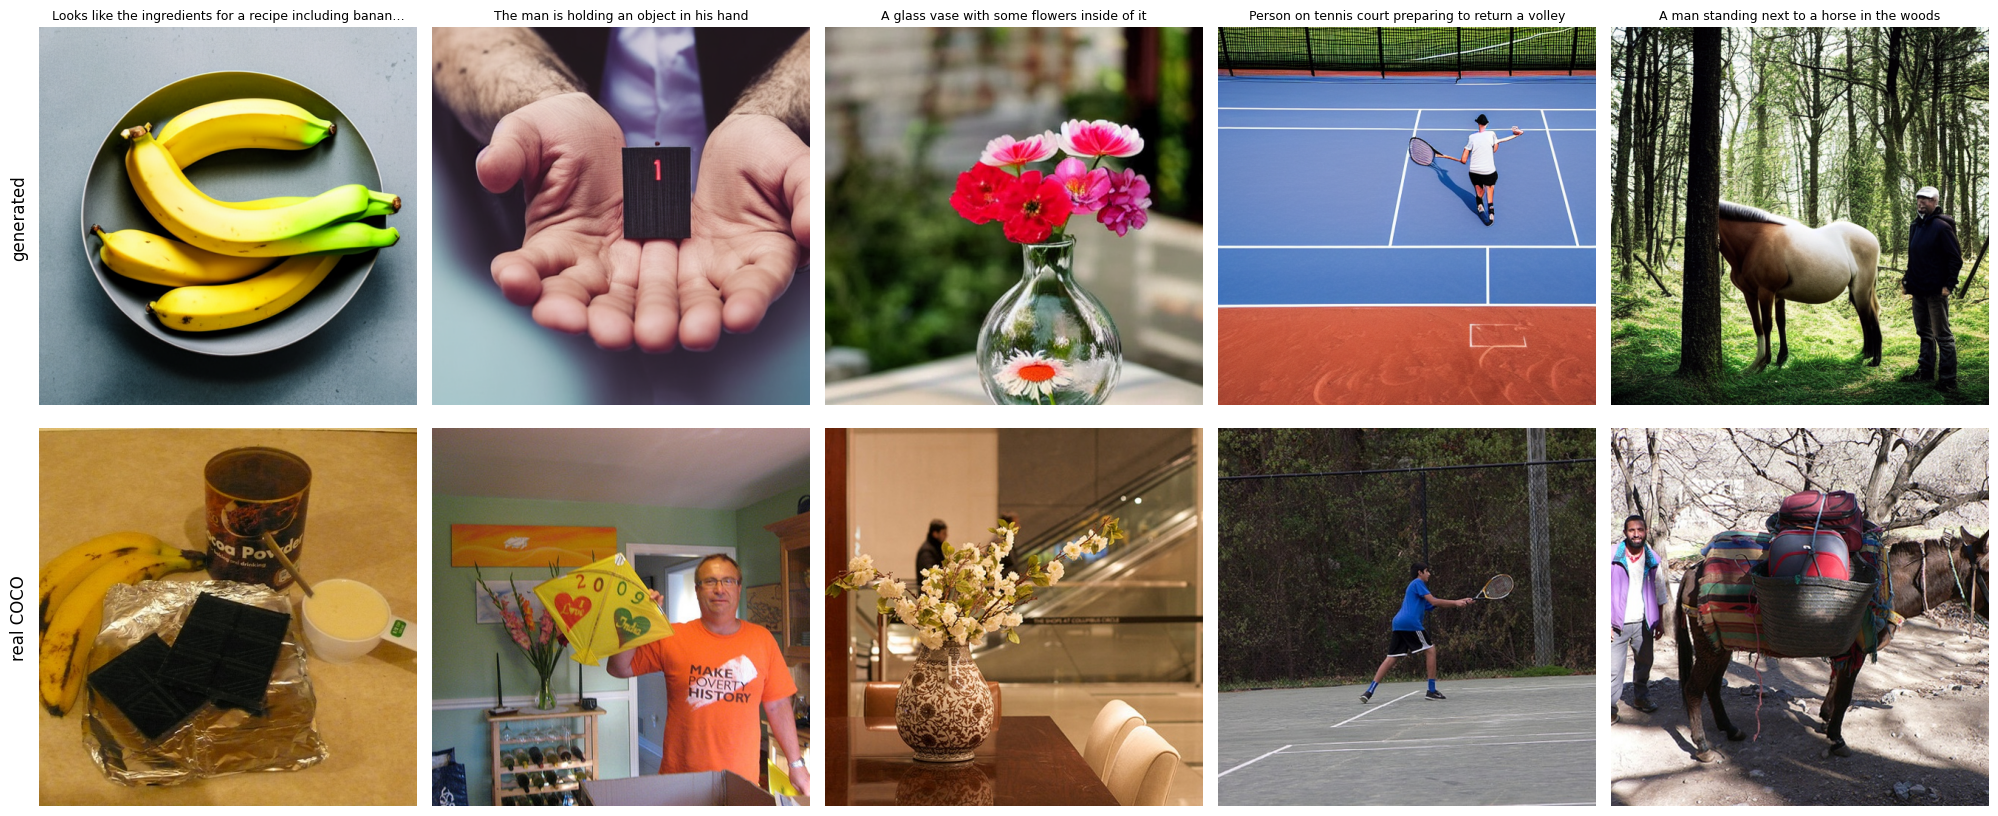

In [5]:
# Generated vs real COCO image
real_files = [subset.loc[subset.image_id == emb["image_ids"][i], "file_name"].item() for i in pick]
IMG_DIR = C.PROC_DIR / f"images_{C.IMAGE_SIZE}"

fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
for j, (img, p, fn) in enumerate(zip(images, prompts, real_files)):
    axes[0, j].imshow(img); axes[0, j].set_title(p[:55] + ("…" if len(p) > 55 else ""), fontsize=9)
    axes[1, j].imshow(load_image(IMG_DIR / fn))
for ax in axes.flat: ax.axis("off")
axes[0, 0].text(-40, 256, "generated", rotation=90, va="center", fontsize=12)
axes[1, 0].text(-40, 256, "real COCO", rotation=90, va="center", fontsize=12)
plt.tight_layout(); plt.savefig(C.SAMPLES_DIR / "baseline_vs_real.png", dpi=100, bbox_inches="tight"); plt.show()

## 3. Check: cached embeddings = pipeline's own text encoder
Same prompt, same seed, two routes. The images should be (near) identical, which proves our text→embedding pipeline matches what SD expects.

In [6]:
a, _ = generate(pipe, prompt_embeds=prompt_embeds[:1], seed=C.SEED, num_steps=C.NUM_STEPS)
b, _ = generate(pipe, prompts=prompts[:1], seed=C.SEED, num_steps=C.NUM_STEPS)
import numpy as np
diff = np.abs(np.asarray(a[0], dtype=int) - np.asarray(b[0], dtype=int)).mean()
print(f"Mean pixel difference (0–255): {diff:.2f}  -> small (< ~2) means the routes match")

Mean pixel difference (0–255): 0.01  -> small (< ~2) means the routes match


## 4. Handwritten prompts vs COCO captions (CLIP score)
Five short handwritten prompts, generated with the same settings as the COCO captions above.
The CLIP score (100 × cosine similarity of image and text embeddings) measures prompt alignment.
For reference, real COCO image–caption pairs score 25.4 (notebook 01).

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 9737.88it/s]


Mean CLIP score | COCO captions: 25.0 | handwritten: 28.0 | real COCO pairs: 25.4


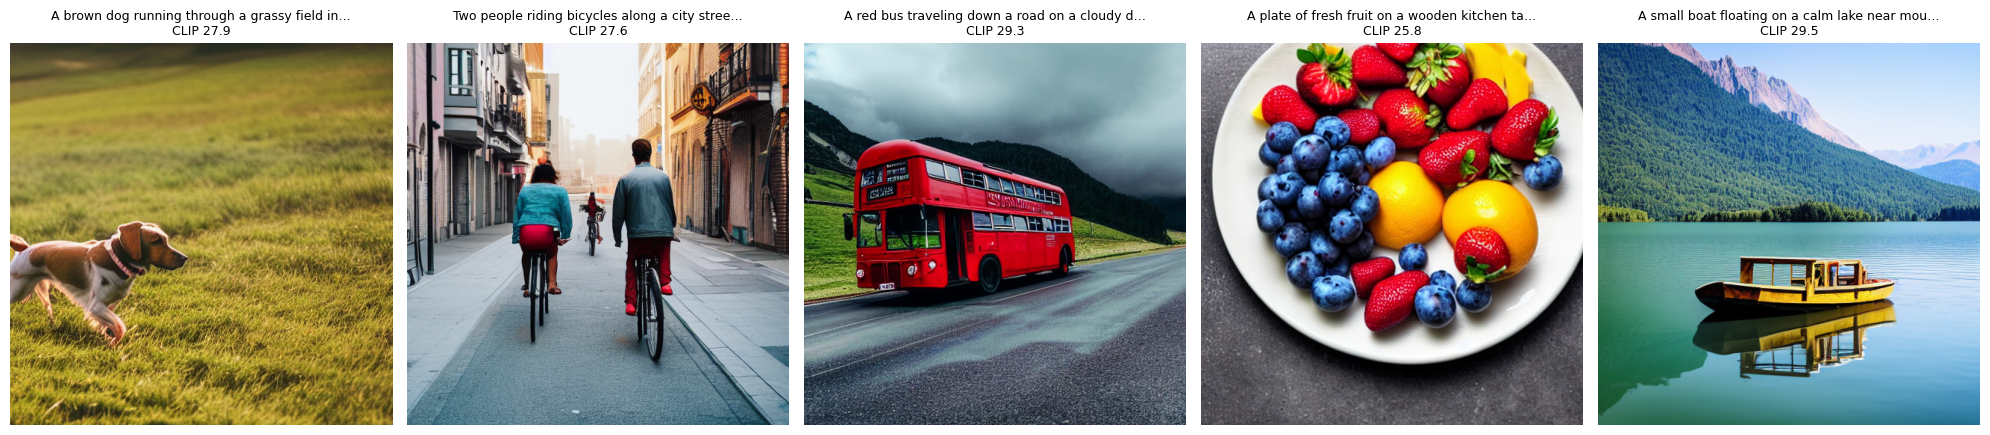

In [7]:
from src.embeddings import ClipEncoder

hw_images = [generate(pipe, prompts=[p], guidance_scale=C.GUIDANCE_SCALE,
                      num_steps=C.NUM_STEPS, seed=s, size=C.IMAGE_SIZE)[0][0]
             for p, s in zip(C.HANDWRITTEN_PROMPTS, C.HANDWRITTEN_SEEDS)]
save_run(hw_images, C.HANDWRITTEN_PROMPTS, C.SAMPLES_DIR / "handwritten",
         dict(model=C.SD_MODEL, scheduler=C.SCHEDULER, guidance_scale=C.GUIDANCE_SCALE,
              num_steps=C.NUM_STEPS, seeds=C.HANDWRITTEN_SEEDS), prefix="handwritten")

enc = ClipEncoder(C.CLIP_MODEL)
def clip_score(imgs, texts):
    _, t = enc.encode_text(texts, return_hidden=False)
    return (100 * (t * enc.encode_images(imgs)).sum(1)).tolist()

coco_scores = clip_score(images, prompts)
hw_scores = clip_score(hw_images, C.HANDWRITTEN_PROMPTS)
mean = lambda xs: sum(xs) / len(xs)
print(f"Mean CLIP score | COCO captions: {mean(coco_scores):.1f} | "
      f"handwritten: {mean(hw_scores):.1f} | real COCO pairs: 25.4")

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, img, p, sc in zip(axes, hw_images, C.HANDWRITTEN_PROMPTS, hw_scores):
    ax.imshow(img); ax.set_title(f"{p[:45]}…\nCLIP {sc:.1f}", fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(C.SAMPLES_DIR / "handwritten_grid.png", dpi=100, bbox_inches="tight"); plt.show()

## 5. Preview for Milestone 2: guidance scale
One prompt, same seed, different classifier-free guidance. Low = loose/diverse, high = literal/saturated.

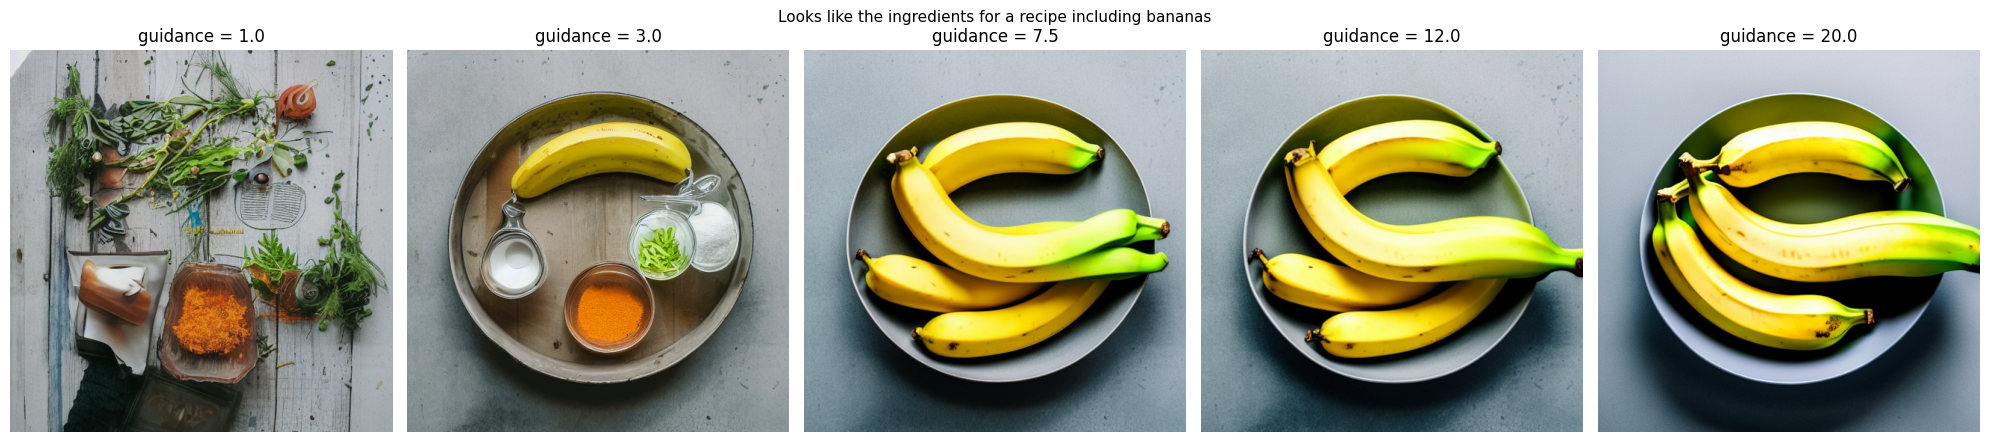

In [8]:
scales = [1.0, 3.0, 7.5, 12.0, 20.0]
p = prompts[0]
grid = [generate(pipe, prompts=[p], guidance_scale=g, num_steps=C.NUM_STEPS, seed=C.SEED)[0][0] for g in scales]

fig, axes = plt.subplots(1, len(scales), figsize=(20, 4.5))
for ax, img, g in zip(axes, grid, scales):
    ax.imshow(img); ax.set_title(f"guidance = {g}"); ax.axis("off")
fig.suptitle(p, fontsize=11); plt.tight_layout()
plt.savefig(C.SAMPLES_DIR / "guidance_preview.png", dpi=100, bbox_inches="tight"); plt.show()

## Observations

**Which prompts worked well or badly?**
- **Well:** single, concrete objects. *Bananas*, *glass vase with flowers* and *man next to a horse in the woods* are realistic and match the caption.
- **Partly:** *person on tennis court* gets the scene right, but the court layout is wrong (clay patch, odd lines), and the player is small and less detailed.
- **Badly:** vague captions. *"The man is holding an object in his hand"* gives close-up hands holding a random black card with a "1" on it, because "an object" gives the model nothing concrete to draw.
- **Handwritten prompts** (short, one subject; same settings as above): mean CLIP score **28.0** vs **25.0** for the COCO captions and 25.4 for real COCO image–caption pairs. Short, concrete prompts align better than real COCO captions. Best: boat on lake (29.5) and red bus (29.3). Lowest: fruit plate (25.8), where the model drew a stone surface instead of the "wooden kitchen table", so CLIP picks up missed details. The dog is small and partly cut off at the frame edge.
- **Generated vs real COCO:** generated images are cleaner and more "stock photo" (centred subject, blurred background). Real COCO photos are cluttered everyday scenes. This gap is what FID will measure in Milestone 3.

**How did guidance change realism vs prompt-faithfulness?** (same prompt and seed)
- **w = 1:** ignores the prompt; a messy scatter of herbs and ingredients with no bananas.
- **w = 3:** follows the prompt loosely; one banana plus small bowls of ingredients, the most natural "recipe" look.
- **w = 7.5 (default):** clearly bananas on a plate. A good balance.
- **w = 12–20:** same layout but colours become oversaturated and contrast harsher. More literal, less realistic.

**Generation time per image:** 80–142 s on CPU (MacBook, no GPU) at 30 steps; ~__ s on Colab T4 (fill in after the Colab run).

**Check:** cached embeddings and SD's own text encoder give the same image (mean pixel difference 0.01), so our text → embedding pipeline matches what Stable Diffusion expects.